# Figure S3

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import load_pupilbetas, DATASET_LABELS
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
DATASET_LABELS= {
    "equalIndifference" : "EqualIndifference",
    "equalRange" : "\nEqualRange",
    "sheng2020" : "Sheng2020"
}

### Pupil GLM fit quality (R^2 per participant)

R2 summary (one-sample t-test vs 0):
  equalIndifference: n=32, mean=0.2824, sd=0.0771, t=20.734, p=4.97e-20
  equalRange: n=30, mean=0.2957, sd=0.0795, t=20.361, p=5.05e-19
  sheng2020: n=63, mean=0.3024, sd=0.0811, t=29.575, p=1.45e-38


/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_77321/611400411.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


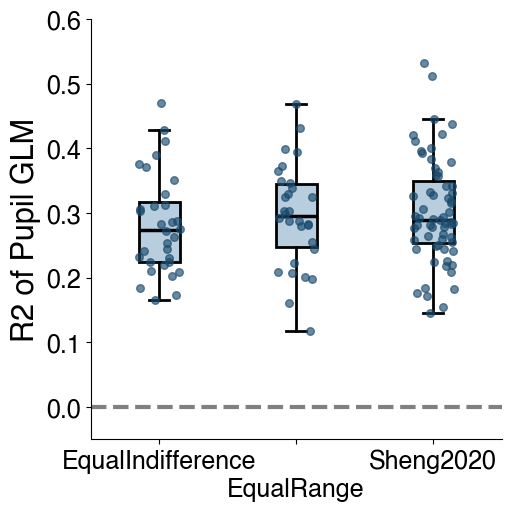

In [3]:
BOX_COLOR = "#B8CEDE"
POINT_COLOR = "#1A4A6E"

betas_df = load_pupilbetas()
r2_per_sub = (
    betas_df.groupby(["sub", "dataset"])["r2"]
    .first()
    .reset_index()
)

print("R2 summary (one-sample t-test vs 0):")
for ds in DATASETS:
    vals = r2_per_sub[r2_per_sub["dataset"] == ds]["r2"].values
    t, p = stats.ttest_1samp(vals, popmean=0, alternative="greater")
    print(f"  {ds}: n={len(vals)}, mean={np.mean(vals):.4f}, "
          f"sd={np.std(vals, ddof=1):.4f}, t={t:.3f}, p={p:.2e}")

data = [r2_per_sub[r2_per_sub["dataset"] == ds]["r2"].values for ds in DATASETS]

fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")
bp = ax.boxplot(
    data, labels=DATASETS, patch_artist=True,
    medianprops=dict(color="black", linewidth=2.5),
    whiskerprops=dict(linewidth=2.0),
    capprops=dict(linewidth=2.0),
    boxprops=dict(linewidth=2.0),
    flierprops=dict(marker="", linestyle="none"),
)
for patch in bp["boxes"]:
    patch.set_facecolor(BOX_COLOR)

rng = np.random.default_rng(0)
for i, vals in enumerate(data, start=1):
    jitter = rng.uniform(-0.15, 0.15, size=len(vals))
    ax.scatter(i + jitter, vals, color=POINT_COLOR, s=30, alpha=0.65, zorder=3)

ax.set_ylim(-0.05, 0.6)
ax.axhline(y=0, color = "grey", linestyle = "--", linewidth = 3)
ax.set_xticklabels([DATASET_LABELS[dataset] for dataset in DATASETS], rotation=0, ha="center")
ax.set_ylabel("R2 of Pupil GLM")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig("saved/figureS3.svg", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
r2_per_sub

,sub,run,dataset,r2
0,1,1,sheng2020,0.244996
1,1,2,sheng2020,0.244996
2,2,1,equalRange,0.349750
3,2,1,sheng2020,0.358270
4,2,2,equalRange,0.349750
...,...,...,...,...
369,123,4,equalIndifference,0.164892
370,124,1,equalRange,0.302700
371,124,2,equalRange,0.302700
372,124,3,equalRange,0.302700
